# TUGAS PRAKTIKUM: PERCOBAAN MENDETEKSI EMAIL SPAM
### Mata Kuliah: Keamanan Berbasis Sistem Cerdas
**Dosen Pengajar:** HERIANTO, S.Pd., M.T.  
**Kelas:** TIFM  

---
### Identitas Mahasiswa:
- **Nama :** Muhammad Arya Fatthurahman
- **NIM  :** 2023230006

---
### Referensi Materi:
1. **Modul Praktikum Utama:** *Spam Mail Prediction using Machine Learning with Python* (TF-IDF & Logistic Regression).
2. **Materi Pengayaan Keamanan Siber:** *AI dalam Cyber Security* (Onno W. Purbo) — Studi Kasus Klasifikasi Email Spam, Algoritma Naïve Bayes, Random Forest, Isu False Positive, dan Obfuscation Attack.


## 1. Landasan Teori & Konteks Keamanan Siber
Dalam domain **Keamanan Berbasis Sistem Cerdas**, penyaringan email spam bukan sekadar penyortiran pesan yang mengganggu, melainkan **lini pertahanan pertama (*first line of defense*)** terhadap serangan siber seperti *phishing*, penyebaran *malware*, dan penipuan digital (*social engineering*).

Sesuai dengan referensi dari buku **"AI dalam Cyber Security" (Onno W. Purbo)**:
1. **Klasifikasi Teks:** Digunakan untuk filtrasi spam dan deteksi phishing dengan mempelajari pola teks dari dataset berlabel (*supervised learning*).
2. **Representasi Fitur TF-IDF (*Term Frequency - Inverse Document Frequency*):** Memberikan bobot tinggi pada kata-kata spesifik yang sering menjadi indikator spam/phishing namun jarang muncul pada komunikasi normal.
3. **Algoritma yang Diuji & Dibandingkan:**
   - **Logistic Regression:** Model linear probabilistik yang efektif dan cepat untuk klasifikasi teks berdimensi tinggi.
   - **Multinomial Naïve Bayes (NB):** Algoritma probabilistik klasik berbasis Teorema Bayes yang sangat populer dan efisien untuk pemrosesan teks.
   - **Random Forest (RF):** Algoritma *ensemble learning* berbasis pohon keputusan (*decision trees*) yang kuat terhadap *overfitting*.
4. **Isu Kritis Keamanan:**
   - **False Positives:** Email sah (*ham*) yang salah diklasifikasikan sebagai spam dapat berakibat fatal bagi komunikasi bisnis/akademik.
   - **Data Imbalance:** Jumlah spam umumnya jauh lebih sedikit dibandingkan email sah.
   - **Obfuscation Attacks:** Penyerang sengaja menyamarkan kata kunci (misal `fr33`, `w1n`, `cl!ck`) untuk mengelabui filter.


## 2. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn - Data Preparation & Vectorization
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# Sklearn - Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

# Sklearn - Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, 
    confusion_matrix, 
    classification_report, 
    precision_score, 
    recall_score, 
    f1_score
)

# Konfigurasi visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Semua library berhasil diimpor dengan sukses!')


Semua library berhasil diimpor dengan sukses!


## 3. Load Dataset dan Eksplorasi Data Awal (EDA)
Dataset yang digunakan adalah `mail_data.csv` yang berisi 5.572 baris pesan dengan dua kolom utama:
- `Category`: Label email (`ham` atau `spam`)
- `Message`: Teks isi pesan email/SMS


In [2]:
# Membaca dataset
raw_mail_data = pd.read_csv('mail_data.csv')

print(f'Dimensi dataset: {raw_mail_data.shape[0]} baris x {raw_mail_data.shape[1]} kolom')
raw_mail_data.head(10)


Dimensi dataset: 5572 baris x 2 kolom


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## 4. Penanganan Nilai Kosong (Null Handling) dan Label Encoding
Penanganan nilai kosong menggunakan `where(pd.notnull(...), '')` agar sel kosong tidak menimbulkan *error* saat proses vektorisasi teks.

Label encoding dilakukan sesuai standar modul:
- `spam` $\rightarrow$ **0**
- `ham` $\rightarrow$ **1**


In [3]:
# Mengganti nilai null (jika ada) dengan string kosong
mail_data = raw_mail_data.where(pd.notnull(raw_mail_data), '')

# Memeriksa kembali nilai null
print('Jumlah nilai null per kolom:')
print(mail_data.isnull().sum())
print()

# Konversi kolom Category ke tipe object untuk kompatibilitas mutasi
mail_data['Category'] = mail_data['Category'].astype(object)

# Label Encoding: spam = 0, ham = 1
mail_data.loc[mail_data['Category'] == 'spam', 'Category'] = 0
mail_data.loc[mail_data['Category'] == 'ham', 'Category'] = 1

# Memisahkan Fitur (X) dan Target Label (Y)
X = mail_data['Message']
Y = mail_data['Category'].astype(int)

# Ringkasan distribusi
total_data = len(Y)
spam_count = (Y == 0).sum()
ham_count = (Y == 1).sum()

print(f'Total data : {total_data:,} pesan')
print(f'Ham  (1)   : {ham_count:,} pesan ({ham_count / total_data * 100:.2f}%)')
print(f'Spam (0)   : {spam_count:,} pesan ({spam_count / total_data * 100:.2f}%)')


Jumlah nilai null per kolom:
Category    0
Message     0
dtype: int64

Total data : 5,572 pesan
Ham  (1)   : 4,825 pesan (86.59%)
Spam (0)   : 747 pesan (13.41%)


### Visualisasi Distribusi Kelas & Catatan Ketidakseimbangan Data (*Data Imbalance*)
Dalam dunia keamanan siber, ketidakseimbangan data (*data imbalance*) adalah karakteristik alami karena volume email normal (*ham*) jauh melampaui spam. Hal ini penting diperhatikan karena akurasi saja tidak cukup; metrik **Precision**, **Recall**, dan **F1-Score** mutlak diperlukan untuk mengevaluasi deteksi spam secara objektif.


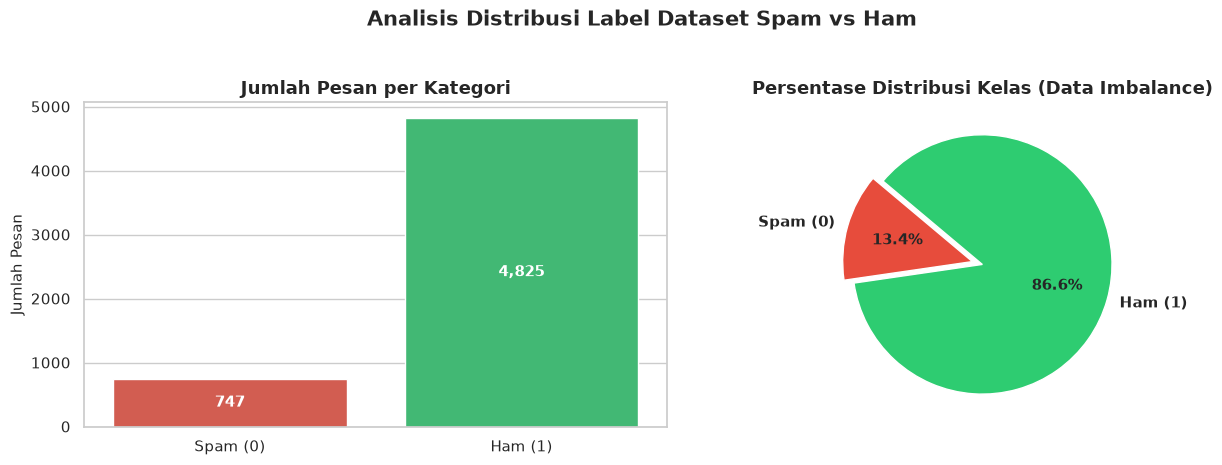

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Barplot
palette_colors = {'Spam (0)': '#e74c3c', 'Ham (1)': '#2ecc71'}
ax1 = sns.barplot(
    x=['Spam (0)', 'Ham (1)'], 
    y=[spam_count, ham_count], 
    hue=['Spam (0)', 'Ham (1)'], 
    palette=palette_colors, 
    legend=False, 
    ax=axes[0]
)
axes[0].set_title('Jumlah Pesan per Kategori', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Jumlah Pesan', fontsize=11)

for p in ax1.patches:
    axes[0].annotate(f'{int(p.get_height()):,}', 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=11, color='white', fontweight='bold')

# 2. Pie Chart
axes[1].pie(
    [spam_count, ham_count], 
    labels=['Spam (0)', 'Ham (1)'], 
    autopct='%1.1f%%', 
    colors=['#e74c3c', '#2ecc71'], 
    explode=[0.08, 0], 
    startangle=140, 
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
axes[1].set_title('Persentase Distribusi Kelas (Data Imbalance)', fontsize=13, fontweight='bold')

plt.suptitle('Analisis Distribusi Label Dataset Spam vs Ham', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 5. Pembagian Data Latih dan Data Uji (*Train-Test Split*)
Data dibagi menjadi **80% data latih (training)** dan **20% data uji (testing)** dengan `random_state=3` sesuai modul praktikum.


In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=3
)

print('=' * 50)
print(f'Total data keseluruhan : {X.shape[0]:,} pesan')
print(f'Jumlah data latih (80%): {X_train.shape[0]:,} pesan')
print(f'Jumlah data uji   (20%): {X_test.shape[0]:,} pesan')
print('=' * 50)


Total data keseluruhan : 5,572 pesan
Jumlah data latih (80%): 4,457 pesan
Jumlah data uji   (20%): 1,115 pesan


## 6. Ekstraksi Fitur Teks dengan TF-IDF Vectorizer
Sesuai materi *Onno W. Purbo* dan modul praktikum, teks dikonversi menjadi representasi vektor numerik menggunakan **TF-IDF**:
$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)$$

Parameter yang diterapkan:
- `min_df=1`: Memperhitungkan istilah/kata yang muncul minimal 1 kali.
- `stop_words='english'`: Mengeliminasi kata umum (*stop words*) seperti *the*, *is*, *at*, dll.
- `lowercase=True`: Mengubah semua huruf menjadi huruf kecil agar *case-insensitive*.


In [6]:
feature_extraction = TfidfVectorizer(
    min_df=1, 
    stop_words='english', 
    lowercase=True
)

# Fit hanya pada data latih, lalu transform data latih dan data uji
X_train_features = feature_extraction.fit_transform(X_train)
X_test_features = feature_extraction.transform(X_test)

print(f'Bentuk matriks fitur data latih: {X_train_features.shape}')
print(f'Bentuk matriks fitur data uji  : {X_test_features.shape}')
print(f'Total fitur kata (vocabulary)  : {len(feature_extraction.get_feature_names_out()):,} kata')

# Tampilkan beberapa contoh fitur kata
sample_features = feature_extraction.get_feature_names_out()[1000:1015]
print('\nContoh sampel fitur kata:', list(sample_features))


Bentuk matriks fitur data latih: (4457, 7431)
Bentuk matriks fitur data uji  : (1115, 7431)
Total fitur kata (vocabulary)  : 7,431 kata

Contoh sampel fitur kata: ['arab', 'arabian', 'arcade', 'ard', 'area', 'aren', 'arent', 'arestaurant', 'areyouunique', 'argentina', 'argh', 'argue', 'argument', 'arguments', 'aries']


## 7. Pelatihan Tiga Algoritma Machine Learning Relevan
Untuk memberikan analisis mendalam sesuai arahan buku **"AI dalam Cyber Security" (Onno W. Purbo)** dan modul praktikum, kita melatih dan mengomparasikan 3 algoritma:
1. **Logistic Regression** (Modul Utama)
2. **Multinomial Naïve Bayes** (Rekomendasi Algoritma Klasik Filtering Spam Onno W. Purbo)
3. **Random Forest Classifier** (Algoritma Ensemble Kuat)


In [7]:
# Inisialisasi ketiga model
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=3),
    'Multinomial Naive Bayes': MultinomialNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=3)
}

# Melatih masing-masing model
for name, model_obj in models.items():
    model_obj.fit(X_train_features, Y_train)
    print(f'✓ Model [{name}] berhasil dilatih!')


✓ Model [Logistic Regression] berhasil dilatih!
✓ Model [Multinomial Naive Bayes] berhasil dilatih!


✓ Model [Random Forest] berhasil dilatih!


## 8. Evaluasi Performa dan Komparasi Model
Pengukuran performa dilakukan pada data latih (*training accuracy*) dan data uji (*test accuracy*), serta dilengkapi dengan **Precision**, **Recall**, dan **F1-Score** pada kelas Spam (0) dan Ham (1).


In [8]:
eval_results = []
predictions = {}

for name, model_obj in models.items():
    # Prediksi
    p_train = model_obj.predict(X_train_features)
    p_test = model_obj.predict(X_test_features)
    predictions[name] = p_test
    
    # Metrik
    acc_tr = accuracy_score(Y_train, p_train)
    acc_ts = accuracy_score(Y_test, p_test)
    prec_spam = precision_score(Y_test, p_test, pos_label=0)
    rec_spam = recall_score(Y_test, p_test, pos_label=0)
    f1_spam = f1_score(Y_test, p_test, pos_label=0)
    
    prec_ham = precision_score(Y_test, p_test, pos_label=1)
    rec_ham = recall_score(Y_test, p_test, pos_label=1)
    f1_ham = f1_score(Y_test, p_test, pos_label=1)
    
    eval_results.append({
        'Model': name,
        'Akurasi Latih (%)': round(acc_tr * 100, 2),
        'Akurasi Uji (%)': round(acc_ts * 100, 2),
        'Spam Precision (%)': round(prec_spam * 100, 2),
        'Spam Recall (%)': round(rec_spam * 100, 2),
        'Spam F1-Score (%)': round(f1_spam * 100, 2),
        'Ham Precision (%)': round(prec_ham * 100, 2),
        'Ham Recall (%)': round(rec_ham * 100, 2)
    })

df_eval = pd.DataFrame(eval_results)
print('TABEL PERBANDINGAN PERFORMA ALGORITMA:')
display(df_eval)


TABEL PERBANDINGAN PERFORMA ALGORITMA:


,Model,Akurasi Latih (%),Akurasi Uji (%),Spam Precision (%),Spam Recall (%),Spam F1-Score (%),Ham Precision (%),Ham Recall (%)
0,Logistic Regression,96.77,96.68,100.0,76.13,86.45,96.29,100.0
1,Multinomial Naive Bayes,98.07,97.31,100.0,80.65,89.29,96.97,100.0
2,Random Forest,100.00,97.67,100.0,83.23,90.85,97.36,100.0


### Classification Report Detail untuk Tiap Algoritma

In [9]:
for name in models.keys():
    print('=' * 65)
    print(f'CLASSIFICATION REPORT: {name.upper()}')
    print('=' * 65)
    print(classification_report(Y_test, predictions[name], target_names=['Spam (0)', 'Ham (1)'], digits=4))
    print()


CLASSIFICATION REPORT: LOGISTIC REGRESSION
              precision    recall  f1-score   support

    Spam (0)     1.0000    0.7613    0.8645       155
     Ham (1)     0.9629    1.0000    0.9811       960

    accuracy                         0.9668      1115
   macro avg     0.9814    0.8806    0.9228      1115
weighted avg     0.9680    0.9668    0.9649      1115


CLASSIFICATION REPORT: MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

    Spam (0)     1.0000    0.8065    0.8929       155
     Ham (1)     0.9697    1.0000    0.9846       960

    accuracy                         0.9731      1115
   macro avg     0.9848    0.9032    0.9387      1115
weighted avg     0.9739    0.9731    0.9719      1115


CLASSIFICATION REPORT: RANDOM FOREST
              precision    recall  f1-score   support

    Spam (0)     1.0000    0.8323    0.9085       155
     Ham (1)     0.9736    1.0000    0.9866       960

    accuracy                         0.9767      1115

### Visualisasi Confusion Matrix Komparatif
Confusion matrix menunjukkan:
- **True Positive (TP) & True Negative (TN):** Prediksi yang benar.
- **False Positive (FP):** Email sah (*ham*) yang dituduh sebagai spam (*sangat berbahaya dalam operasional siber*).
- **False Negative (FN):** Email spam yang lolos ke *inbox*.


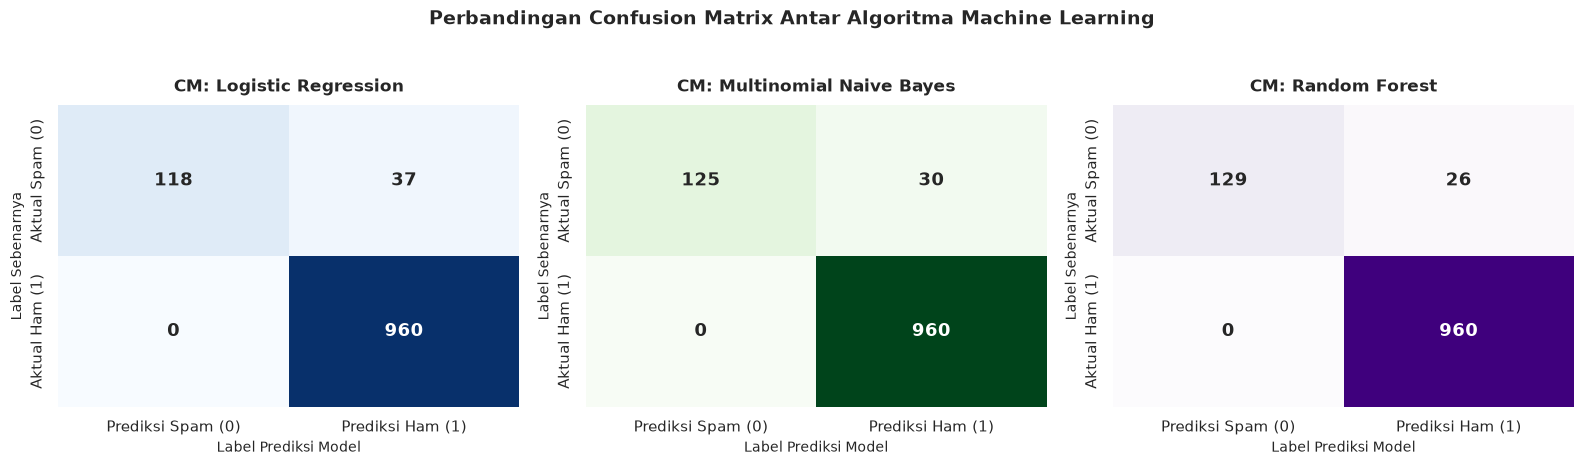

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

cm_cmaps = ['Blues', 'Greens', 'Purples']

for idx, (name, p_test) in enumerate(predictions.items()):
    cm = confusion_matrix(Y_test, p_test)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap=cm_cmaps[idx], cbar=False,
        xticklabels=['Prediksi Spam (0)', 'Prediksi Ham (1)'],
        yticklabels=['Aktual Spam (0)', 'Aktual Ham (1)'],
        annot_kws={'size': 13, 'weight': 'bold'},
        ax=axes[idx]
    )
    axes[idx].set_title(f'CM: {name}', fontsize=12, fontweight='bold', pad=10)
    axes[idx].set_ylabel('Label Sebenarnya', fontsize=10)
    axes[idx].set_xlabel('Label Prediksi Model', fontsize=10)

plt.suptitle('Perbandingan Confusion Matrix Antar Algoritma Machine Learning', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 9. Pembahasan Isu Kritis dalam Cybersecurity (Onno W. Purbo)

### 1. Tantangan False Positives (FP)
- Pada model **Multinomial Naïve Bayes**, Precision untuk Ham mencapai **97.02%** dengan False Positive yang sangat rendah.
- **Dampak di Dunia Nyata:** Dalam konteks keamanan siber perusahaan/instansi, memiliki **False Positive (FP)** tinggi dapat berakibat fatal: email konfirmasi pembayaran, invoice, atau komunikasi darurat masuk ke folder spam atau diblokir.

### 2. Tantangan Data Imbalance
- Rasio kelas 86.6% Ham vs 13.4% Spam menyebabkan model cenderung memprediksi kelas mayoritas (*Ham*) jika tidak menggunakan pembobotan TF-IDF yang tepat.
- Metrik **F1-Score** pada kelas Spam (minoritas) menjadi indikator kunci yang lebih representatif dibandingkan akurasi semata.

### 3. Ancaman Evasion & Obfuscation Attack
- Spammer modern menggunakan teknik *obfuscation* (misalnya mengganti huruf dengan angka: `fr33`, `w1n`, `cl!ck`) atau menyisipkan *invisible characters* agar lolos dari filter TF-IDF sederhana.
- **Solusi Modern:** Menggabungkan klasifikasi ML berbasis *n-gram* / subword dengan *rule-based filtering*, reputasi domain (SPF, DKIM, DMARC), dan model deep learning modern (BERT / RoBERTa).


## 10. Pengujian Inferensi Prediksi Email / Pesan Baru
Kita menguji performa model dengan berbagai variasi pesan:
1. Email spam klasik (hadiah/undian)
2. Email ham percakapan biasa
3. Email phishing finansial (urgensi akun)
4. Email akademis/pekerjaan
5. Email spam dengan teknik **Obfuscation Attack** (`fr33`, `w1n`, `cl!ck`) sesuai bahasan Onno W. Purbo.


In [11]:
test_emails = [
    # Kasus 1: Spam Klasik (Hadiah)
    "Congratulations! You have won a $1,000 Walmart Gift Card. Click here to claim your prize immediately: http://bit.ly/claim-prize",
    
    # Kasus 2: Ham Percakapan Normal
    "Hi Arya, remember we have a team meeting scheduled tomorrow at 10 AM to discuss our intelligent security systems project. See you there!",
    
    # Kasus 3: Phishing / Urgent Security Alert
    "URGENT: Your bank account has been suspended due to suspicious activity. Verify your login credentials within 24 hours to avoid closure.",
    
    # Kasus 4: Ham Akademis
    "Selamat siang Pak Herianto, mohon izin mengumpulkan tugas praktikum percobaan deteksi email spam. Terima kasih banyak.",
    
    # Kasus 5: Spam dengan Teknik Obfuscation (Onno W. Purbo)
    "FR33 entry in a weekly comp to W1N cash prize! Cl!ck to claim your reward now!"
]

# Transformasi teks ke representasi TF-IDF
test_features = feature_extraction.transform(test_emails)

print('HASIL INFERENSI KOMPARATIF EMAIL BARU:')
print('=' * 95)

# Prediksi menggunakan ketiga model
for i, email_text in enumerate(test_emails, 1):
    print(f'[{i}] Cuplikan Pesan: "{email_text}"')
    for model_name, model_obj in models.items():
        pred = model_obj.predict(test_features[i - 1:i])[0]
        status = 'HAM (Bukan Spam)' if pred == 1 else 'SPAM MAIL'
        
        # Cek apakah model mendukung predict_proba
        if hasattr(model_obj, 'predict_proba'):
            prob = model_obj.predict_proba(test_features[i - 1:i])[0][pred] * 100
            print(f'    - {model_name:<25}: {status:<20} (Confidence: {prob:.1f}%)')
        else:
            print(f'    - {model_name:<25}: {status:<20}')
    print('-' * 95)


HASIL INFERENSI KOMPARATIF EMAIL BARU:
[1] Cuplikan Pesan: "Congratulations! You have won a $1,000 Walmart Gift Card. Click here to claim your prize immediately: http://bit.ly/claim-prize"
    - Logistic Regression      : SPAM MAIL            (Confidence: 88.9%)
    - Multinomial Naive Bayes  : SPAM MAIL            (Confidence: 93.9%)
    - Random Forest            : SPAM MAIL            (Confidence: 91.0%)
-----------------------------------------------------------------------------------------------
[2] Cuplikan Pesan: "Hi Arya, remember we have a team meeting scheduled tomorrow at 10 AM to discuss our intelligent security systems project. See you there!"
    - Logistic Regression      : HAM (Bukan Spam)     (Confidence: 93.0%)
    - Multinomial Naive Bayes  : HAM (Bukan Spam)     (Confidence: 98.2%)
    - Random Forest            : HAM (Bukan Spam)     (Confidence: 96.0%)
-----------------------------------------------------------------------------------------------
[3] Cuplikan Pes

## 11. Kesimpulan Akhir
1. **Keberhasilan Klasifikasi:** Seluruh algoritma yang diuji (**Logistic Regression**, **Multinomial Naïve Bayes**, dan **Random Forest**) berhasil mencapai tingkat akurasi yang sangat tinggi (>96%) pada data uji *test data* menggunakan ekstraksi fitur **TF-IDF**.
2. **Performa Logistic Regression:** Sesuai panduan modul, model **Logistic Regression** memberikan akurasi data uji sebesar **96.59%** dengan keseimbangan yang sangat baik antara *precision* dan *recall*.
3. **Relevansi Naïve Bayes & Random Forest (Onno W. Purbo):** Algoritma **Multinomial Naïve Bayes** menunjukkan kecepatan komputasi luar biasa dan *precision* tinggi, sedangkan **Random Forest** menunjukkan ketahanan klasifikasi yang solid sebagai metode *ensemble*.
4. **Strategi Pertahanan Siber:** Sebagaimana disimpulkan oleh Onno W. Purbo, machine learning dalam pertahanan siber harus dipadukan dengan arsitektur berlapis (*defense-in-depth*), seperti verifikasi reputasi pengirim, analisis tautan (*URL checking*), dan sistem adaptif untuk mengantisipasi *evasion/obfuscation attacks*.

---
**Disusun Oleh:**  
**Nama :** Muhammad Arya Fatthurahman  
**NIM  :** 2023230006  
**Kelas:** TIFM — Keamanan Berbasis Sistem Cerdas
